# BENCHMARK ML Methods On 1 model per Participant - leave a kss out, KSS 4 folds

## 1. Imports

In [ ]:
import os
import re
import json
import time
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    confusion_matrix,
    log_loss,
    brier_score_loss,
)

import warnings
warnings.filterwarnings('ignore')

HAS_XGB = False
HAS_CAT = False

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print("XGBoost disponible.")
except Exception as e:
    print("XGBoost non disponible :", e)

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
    print("CatBoost disponible.")
except Exception as e:
    print("CatBoost non disponible :", e)


In [ ]:
# 1. Masquer tous les warnings Python (Scikit-Learn, CatBoost, etc.)
warnings.filterwarnings("ignore")

# 2. Masquer spécifiquement les warnings Pandas (PerformanceWarning / Fragmentation)
warnings.simplefilter(action="ignore", category=FutureWarning)
try:
    from pandas.errors import PerformanceWarning

    warnings.simplefilter(action="ignore", category=PerformanceWarning)
except ImportError:
    pass

# 3. Variable d'environnement pour bloquer les warnings au niveau système
os.environ["PYTHONWARNINGS"] = "ignore"

## 2. Configuration

In [ ]:


ROOT_DATASETS = Path("DATASETS_2")

RUN_DATASET_FOLDERS = [
    "short_step10_nirs20_bio60",
    "medium_step15_nirs30_bio120",
    "long_step30_nirs60_bio180",
]

RUN_DATASET_FILES = [
    "ds_nirs.csv",
    "ds_nirs_ecg.csv",
    "ds_nirs_rsp.csv",
    "ds_nirs_ecg_rsp.csv",
]

OUTPUT_DIR = Path("RESULTS_ML_BY_PARTICIPANT_LEAVE_ONE_KSS_OUT-4FOLDScrossval")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_OUT = OUTPUT_DIR / "recap_ML_by_participant_leave-one-kss-out_4folds-crossval.xlsx"

COL_PARTICIPANT = "Participant"
COL_LABEL = "KSS_label"
COL_KSS = "KSS"

KSS_ALERTE_MAX = 5
KSS_SOMNOLENT_MIN = 7

SEED = 42

TEST_FRAC_TARGET = 0.20
TIME_BINS_PER_KSS = 5

MAX_NAN_RATE_FEATURE = 0.40

SCALER_MODE = "standard"
# "standard" = StandardScaler fit train uniquement
# "robust"   = RobustScaler fit train uniquement
# "none"     = pas de normalisation

CORR_FNIRS = 0.90
TOPK_SCORE_METHOD = "mutual_info"
K_FNIRS_PREFILTER = 200

RUN_REDUCTION_MODES = [
    "full_decorr_fnirs",
    "fnirs_topk_corr_k80",
    "fnirs_global_chrom",
    "fnirs_hemi_chrom",
    "fnirs_global_chrom_decorr",
    "fnirs_hemi_chrom_decorr",
]

RUN_MODEL_NAMES = [
    "LogReg_ElasticNet",
    "Linear_SVM",
    "LogReg_L2",
    #"RBF_SVM",
    "RandomForest",
    "ExtraTrees",
    #"HistGradientBoosting",
    "XGBoost",
    "CatBoost",
]

DEFAULT_MAX_WIN_MS = 180_000
Z_EPS = 1e-8

SPLIT_MODE = "leave_one_kss_oof"
KSS_EPISODE_COL = "KSS"

MIN_EPISODES_PER_CLASS = 2


## 3. Colonnes features robustes

In [ ]:

FEATURE_PREFIXES = ("fnirs", "ecg", "hrv", "rsp", "rsa")

PREF = {
    "fNIRS": ("fnirs",),
    "ECG": ("ecg", "hrv"),
    "RSP": ("rsp",),
    "RSA": ("rsa",),
}

def _col_lower(c):
    return str(c).strip().lower()

def is_feature_col(c):
    return _col_lower(c).startswith(FEATURE_PREFIXES)

def select_feature_cols(cols):
    return [c for c in cols if is_feature_col(c)]

def get_cols_by_prefix(X_or_cols, prefixes):
    cols = X_or_cols.columns if isinstance(X_or_cols, pd.DataFrame) else X_or_cols
    prefixes = tuple(str(p).lower() for p in prefixes)
    return [c for c in cols if _col_lower(c).startswith(prefixes)]

def get_modality_cols(X_or_cols, modality):
    return get_cols_by_prefix(X_or_cols, PREF[modality])

def infer_modalities_from_columns(cols):
    mods = []
    for mod in ["fNIRS", "ECG", "RSP", "RSA"]:
        if len(get_modality_cols(cols, mod)) > 0:
            mods.append(mod)
    return mods

def has_fnirs(cols):
    return len(get_modality_cols(cols, "fNIRS")) > 0

def infer_feature_modality(feature):
    f = _col_lower(feature)
    if f.startswith("fnirs"):
        return "fNIRS"
    if f.startswith(("ecg", "hrv")):
        return "ECG"
    if f.startswith("rsp"):
        return "RSP"
    if f.startswith("rsa"):
        return "RSA"
    return "OTHER"

def clean_feature_columns(df):
    bad = [
        c for c in df.columns
        if str(c).startswith("Unnamed") or str(c).lower() in ["index", "level_0"]
    ]
    if bad:
        df = df.drop(columns=bad, errors="ignore")
    return df, bad


## 4. Mapping fNIRS

In [ ]:

HEMISPHERE_MAP = {
    "Rx1Tx1": "G",
    "Rx1Tx3": "G",
    "Rx2Tx1": "G",
    "Rx2Tx3": "G",
    "Rx3Tx4": "D",
    "Rx3Tx5": "D",
    "Rx4Tx4": "D",
    "Rx4Tx5": "D",
}


HB_ALIASES = {
    "O2Hb": "O2Hb",
    "HbO": "O2Hb",
    "HbO2": "O2Hb",
    "oxyHb": "O2Hb",
    "OxyHb": "O2Hb",
    "HHb": "HHb",
    "HbR": "HHb",
    "HBR": "HHb",
    "deoxyHb": "HHb",
    "DeoxyHb": "HHb",
    "tHb": "tHb",
    "THb": "tHb",
    "HbT": "tHb",
    "hbt": "tHb",
    "HbTot": "tHb",
    "TotalHb": "tHb",
    "HbDiff": "HbDiff",
    "Hbdiff": "HbDiff",
    "HbDIFF": "HbDiff",
    "Hb_Diff": "HbDiff",
    "hbdiff": "HbDiff",
}

HB_TOKENS = list(HB_ALIASES.keys())

def parse_fnirs_col(col):
    if not _col_lower(col).startswith("fnirs"):
        return None

    parts = str(col).split("_")
    if len(parts) < 3:
        return None

    hb_idx = None
    hb_raw = None

    for i, p in enumerate(parts):
        if p in HB_TOKENS:
            hb_idx = i
            hb_raw = p
            break

    if hb_idx is None:
        return None

    chrom = HB_ALIASES.get(hb_raw, hb_raw)
    channel = "_".join(parts[1:hb_idx])

    feat_parts = parts[hb_idx + 1:]
    if len(feat_parts) > 0 and str(feat_parts[0]).isdigit():
        feat_parts = feat_parts[1:]

    feature = "_".join(feat_parts) if len(feat_parts) else "value"

    return {
        "channel": channel if channel else "unknown_channel",
        "chrom": chrom,
        "feature": feature,
    }

def fit_fnirs_aggregation_mapping(cols, mode):
    fnirs_cols = get_modality_cols(cols, "fNIRS")
    if len(fnirs_cols) == 0:
        return {}

    if mode not in ["fnirs_global_chrom", "fnirs_hemi_chrom"]:
        return {}

    parsed = {}
    for c in fnirs_cols:
        info = parse_fnirs_col(c)
        if info is not None:
            parsed[c] = info

    if len(parsed) == 0:
        print("[WARNING] Aucune colonne fNIRS parsable.")
        return {}

    if mode == "fnirs_hemi_chrom":
        missing_channels = sorted({
            info["channel"]
            for info in parsed.values()
            if info["channel"] not in HEMISPHERE_MAP
        })
        if missing_channels:
            raise ValueError(f"HEMISPHERE_MAP incomplet. Canaux manquants : {missing_channels}")

    groups = defaultdict(list)

    for c, info in parsed.items():
        chrom = info["chrom"]
        feat = info["feature"]
        channel = info["channel"]

        if mode == "fnirs_global_chrom":
            new_name = f"fNIRS_GLOBAL_{chrom}_{feat}"
        else:
            hemi = HEMISPHERE_MAP[channel]
            new_name = f"fNIRS_HEMI_{hemi}_{chrom}_{feat}"

        groups[new_name].append(c)

    return dict(groups)

def apply_fnirs_aggregation(X, mapping):
    if len(mapping) == 0:
        return X.copy()

    fnirs_cols = set(get_modality_cols(X, "fNIRS"))
    non_fnirs_cols = [c for c in X.columns if c not in fnirs_cols]

    X_out = X[non_fnirs_cols].copy()

    for new_col, old_cols in mapping.items():
        existing = [c for c in old_cols if c in X.columns]
        X_out[new_col] = X[existing].mean(axis=1, skipna=True) if existing else np.nan

    return X_out


## 5. Split purgé sans recouvrement

In [ ]:
def infer_max_window_ms_from_path(csv_path):
    s = str(csv_path).lower()
    m = re.search(r"nirs(\d+)_bio(\d+)", s)
    if m:
        nirs_s = int(m.group(1))
        bio_s = int(m.group(2))
        return max(nirs_s, bio_s) * 1000
    return DEFAULT_MAX_WIN_MS


In [ ]:
def get_center_ms(df):
    if "Epoch_center_rel_ms" in df.columns:
        return pd.to_numeric(df["Epoch_center_rel_ms"], errors="coerce")

    if "Epoch_center_rel_s" in df.columns:
        return pd.to_numeric(df["Epoch_center_rel_s"], errors="coerce") * 1000.0

    if "Epoch" in df.columns and "step_ms" in df.columns:
        return pd.to_numeric(df["Epoch"], errors="coerce") * pd.to_numeric(df["step_ms"], errors="coerce")

    # fallback
    return pd.Series(np.arange(len(df), dtype=float), index=df.index) * 10_000.0


def get_window_ms(df):
    win_cols = [c for c in ["win_fNIRS_ms", "win_ECG_ms", "win_RSP_ms"] if c in df.columns]

    if win_cols:
        W = df[win_cols].apply(pd.to_numeric, errors="coerce").max(axis=1)
        return W.replace([np.inf, -np.inf], np.nan).fillna(60_000).clip(lower=1).astype(float)

    # mode short par défaut
    return pd.Series(60_000.0, index=df.index)


def intervals_overlap(c1, w1, c2, w2):
    return np.abs(c1 - c2) < ((w1 + w2) / 2.0)


In [ ]:
def participant_kss_episode_summary(df_p, y):
    tab = (
        df_p[[KSS_EPISODE_COL]]
        .copy()
        .assign(y=y.loc[df_p.index].values)
        .groupby(KSS_EPISODE_COL)
        .agg(
            n_windows=("y", "size"),
            y_unique=("y", "nunique"),
            y_value=("y", "first"),
        )
        .reset_index()
    )
    return tab


def make_leave_one_kss_splits(df_p, y):
    if KSS_EPISODE_COL not in df_p.columns:
        raise RuntimeError(f"Colonne épisode absente : {KSS_EPISODE_COL}")

    ep_tab = participant_kss_episode_summary(df_p, y)

    # Sécurité : un questionnaire KSS doit correspondre à une seule classe
    if (ep_tab["y_unique"] > 1).any():
        bad = ep_tab.loc[ep_tab["y_unique"] > 1, KSS_EPISODE_COL].tolist()
        raise RuntimeError(f"Épisodes KSS avec labels mixtes : {bad}")

    n_alert = int((ep_tab["y_value"] == 0).sum())
    n_sleep = int((ep_tab["y_value"] == 1).sum())

    if n_alert < MIN_EPISODES_PER_CLASS or n_sleep < MIN_EPISODES_PER_CLASS:
        raise RuntimeError(
            f"Participant non éligible : épisodes alertes={n_alert}, somnolents={n_sleep}. "
            f"Il faut au moins {MIN_EPISODES_PER_CLASS} par classe."
        )

    episodes = ep_tab[KSS_EPISODE_COL].tolist()
    splits = []

    for fold_id, test_ep in enumerate(episodes, start=1):
        test_idx = df_p[df_p[KSS_EPISODE_COL] == test_ep].index.tolist()
        train_idx = df_p[df_p[KSS_EPISODE_COL] != test_ep].index.tolist()

        if len(train_idx) == 0 or len(test_idx) == 0:
            continue

        ytr = y.loc[train_idx]
        yte = y.loc[test_idx]

        if len(np.unique(ytr)) < 2:
            continue

        splits.append({
            "fold_id": fold_id,
            "test_kss": test_ep,
            "train_kss": sorted(df_p.loc[train_idx, KSS_EPISODE_COL].unique().tolist()),
            "train_idx": train_idx,
            "test_idx": test_idx,
            "test_class": int(yte.iloc[0]),
        })

    if len(splits) == 0:
        raise RuntimeError("Aucun fold leave-one-KSS valide.")

    return splits


## 6. CHargement Datasets

In [ ]:

def load_and_prepare_dataset(csv_path):
    df = pd.read_csv(csv_path)
    df["_split_window_ms"] = infer_max_window_ms_from_path(csv_path)
    df = df.replace([np.inf, -np.inf], np.nan)
    df, bad_cols = clean_feature_columns(df)

    if COL_PARTICIPANT not in df.columns:
        raise ValueError(f"{COL_PARTICIPANT} absent de {csv_path}")

    if COL_LABEL not in df.columns:
        raise ValueError(f"{COL_LABEL} absent de {csv_path}")

    kss_label = pd.to_numeric(df[COL_LABEL], errors="coerce")

    df = df[(kss_label <= KSS_ALERTE_MAX) | (kss_label >= KSS_SOMNOLENT_MIN)].copy()
    df["y"] = (pd.to_numeric(df[COL_LABEL], errors="coerce") >= KSS_SOMNOLENT_MIN).astype(int)

    feature_cols = select_feature_cols(df.columns)

    if len(feature_cols) == 0:
        raise ValueError(f"Aucune feature trouvée avec préfixes {FEATURE_PREFIXES} dans {csv_path}")

    for c in feature_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.reset_index(drop=True)

    X = df[feature_cols].copy()
    y = df["y"].copy()

    return df, X, y, bad_cols

def dataset_report(csv_path, df, X, y, bad_cols):
    return {
        "csv_path": str(csv_path),
        "dataset_folder": Path(csv_path).parent.name,
        "dataset_file": Path(csv_path).name,
        "n_rows": len(df),
        "n_features": X.shape[1],
        "n_participants": df[COL_PARTICIPANT].nunique(),
        "class_0": int((y == 0).sum()),
        "class_1": int((y == 1).sum()),
        "class_1_rate": float((y == 1).mean()) if len(y) else np.nan,
        "nan_total": int(X.isna().sum().sum()),
        "nan_rate_global": float(X.isna().sum().sum() / X.size) if X.size else np.nan,
        "modalities": ",".join(infer_modalities_from_columns(X.columns)),
        "n_fnirs_features": len(get_modality_cols(X, "fNIRS")),
        "n_ecg_features": len(get_modality_cols(X, "ECG")),
        "n_rsp_features": len(get_modality_cols(X, "RSP")),
        "n_rsa_features": len(get_modality_cols(X, "RSA")),
        "dropped_bad_index_cols": ",".join(bad_cols),
    }


## 7. Preprocessing

In [ ]:

def drop_bad_nan_features(Xtr, Xte, max_nan_rate=0.40):
    nan_rate = Xtr.isna().mean()
    cols_drop = nan_rate[nan_rate > max_nan_rate].index.tolist()

    return (
        Xtr.drop(columns=cols_drop, errors="ignore"),
        Xte.drop(columns=cols_drop, errors="ignore"),
        cols_drop,
    )

def drop_constant_features(Xtr, Xte):
    nunique = Xtr.nunique(dropna=True)
    cols_drop = nunique[nunique <= 1].index.tolist()

    return (
        Xtr.drop(columns=cols_drop, errors="ignore"),
        Xte.drop(columns=cols_drop, errors="ignore"),
        cols_drop,
    )

def impute_median(Xtr, Xte):
    imputer = SimpleImputer(strategy="median")

    Xtr_imp = pd.DataFrame(
        imputer.fit_transform(Xtr),
        columns=Xtr.columns,
        index=Xtr.index,
    )

    Xte_imp = pd.DataFrame(
        imputer.transform(Xte),
        columns=Xte.columns,
        index=Xte.index,
    )

    Xtr_imp = Xtr_imp.fillna(0)
    Xte_imp = Xte_imp.fillna(0)

    return Xtr_imp, Xte_imp, imputer

def scale_train_test(Xtr, Xte, mode="standard"):
    if mode == "none":
        return Xtr.copy(), Xte.copy(), None

    if mode == "standard":
        scaler = StandardScaler()
    elif mode == "robust":
        scaler = RobustScaler()
    else:
        raise ValueError("SCALER_MODE doit être 'standard', 'robust' ou 'none'.")

    Xtr_s = pd.DataFrame(
        scaler.fit_transform(Xtr),
        columns=Xtr.columns,
        index=Xtr.index,
    )

    Xte_s = pd.DataFrame(
        scaler.transform(Xte),
        columns=Xte.columns,
        index=Xte.index,
    )

    return Xtr_s, Xte_s, scaler


## 8. Décorrelation fNIRS et TOP-K

In [ ]:

def safe_scores(X_mod, y, score_method="mutual_info", random_state=42):
    if X_mod.shape[1] == 0:
        return np.array([])

    if len(np.unique(y)) < 2:
        return np.zeros(X_mod.shape[1])

    if score_method == "mutual_info":
        scores = mutual_info_classif(
            X_mod,
            y,
            random_state=random_state,
            discrete_features=False,
        )
    elif score_method == "f_classif":
        scores, _ = f_classif(X_mod, y)
    else:
        raise ValueError("score_method doit être 'mutual_info' ou 'f_classif'.")

    return np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

def compute_feature_scores(Xtr, ytr, score_method="mutual_info", random_state=42):
    scores = safe_scores(Xtr, ytr, score_method=score_method, random_state=random_state)
    return pd.Series(scores, index=Xtr.columns, name="score")

def correlation_prune_by_score(Xtr, feature_scores, candidate_cols, corr_threshold=0.95, max_features=None):
    candidate_cols = [c for c in candidate_cols if c in Xtr.columns]

    if len(candidate_cols) == 0:
        return [], []

    ordered_cols = (
        feature_scores
        .reindex(candidate_cols)
        .fillna(0.0)
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    corr = Xtr[ordered_cols].corr().abs()

    kept = []
    dropped_corr = []

    for c in ordered_cols:
        if not kept:
            kept.append(c)
        else:
            max_corr = corr.loc[c, kept].max()
            if max_corr >= corr_threshold:
                dropped_corr.append(c)
            else:
                kept.append(c)

        if max_features is not None and len(kept) >= max_features:
            break

    return kept, dropped_corr

def decorrelate_fnirs_keep_non_fnirs(Xtr, ytr, Xte, corr_threshold=0.95, score_method="mutual_info"):
    fnirs_cols = get_modality_cols(Xtr, "fNIRS")
    non_fnirs_cols = [c for c in Xtr.columns if c not in set(fnirs_cols)]

    if len(fnirs_cols) == 0:
        return Xtr.copy(), Xte.copy(), Xtr.columns.tolist(), pd.DataFrame(), []

    scores_fnirs = compute_feature_scores(Xtr[fnirs_cols], ytr, score_method=score_method, random_state=SEED)

    kept_fnirs, dropped_corr = correlation_prune_by_score(
        Xtr=Xtr,
        feature_scores=scores_fnirs,
        candidate_cols=fnirs_cols,
        corr_threshold=corr_threshold,
        max_features=None,
    )

    final_cols = list(dict.fromkeys(kept_fnirs + non_fnirs_cols))

    score_df = (
        scores_fnirs
        .reset_index()
        .rename(columns={"index": "feature", "score": "score"})
        .sort_values("score", ascending=False)
    )
    score_df["modality"] = "fNIRS"
    score_df["selected_final"] = score_df["feature"].isin(kept_fnirs)

    return Xtr[final_cols], Xte[final_cols], final_cols, score_df, dropped_corr

def parse_topk_from_reduction_mode(reduction_mode):
    m = re.search(r"_k(\d+)$", str(reduction_mode))
    return int(m.group(1)) if m else None

def select_fnirs_topk_decorrelated_keep_non_fnirs(
    Xtr,
    ytr,
    Xte,
    k_final=80,
    k_prefilter=200,
    corr_threshold=0.95,
    score_method="mutual_info",
):
    fnirs_cols = get_modality_cols(Xtr, "fNIRS")
    non_fnirs_cols = [c for c in Xtr.columns if c not in set(fnirs_cols)]

    if len(fnirs_cols) == 0:
        return Xtr.copy(), Xte.copy(), Xtr.columns.tolist(), pd.DataFrame(), []

    scores_fnirs = compute_feature_scores(Xtr[fnirs_cols], ytr, score_method=score_method, random_state=SEED)

    score_df = (
        scores_fnirs
        .reset_index()
        .rename(columns={"index": "feature", "score": "score"})
        .sort_values("score", ascending=False)
    )
    score_df["modality"] = "fNIRS"

    k_prefilter_eff = min(max(k_final, k_prefilter), len(score_df))
    pre_cols = score_df.head(k_prefilter_eff)["feature"].tolist()

    kept_fnirs, dropped_corr = correlation_prune_by_score(
        Xtr=Xtr,
        feature_scores=scores_fnirs,
        candidate_cols=pre_cols,
        corr_threshold=corr_threshold,
        max_features=k_final,
    )

    final_cols = list(dict.fromkeys(kept_fnirs + non_fnirs_cols))

    score_df["selected_final"] = score_df["feature"].isin(kept_fnirs)

    return Xtr[final_cols], Xte[final_cols], final_cols, score_df, dropped_corr


## 9. Modèles et métriques

In [ ]:

def get_models(seed=42):
    models = {}

    models["LogReg_ElasticNet"] = LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=0.5,
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=seed,
        n_jobs=-1,
    )
    models["LogReg_L2"] = LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=seed,
    )

    models["Linear_SVM"] = LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=20000,
        random_state=seed,
    )

    models["RBF_SVM"] = SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=False,
        random_state=seed,
    )

    models["RandomForest"] = RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed,
    )

    models["ExtraTrees"] = ExtraTreesClassifier(
        n_estimators=500,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed,
    )

    models["HistGradientBoosting"] = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        l2_regularization=0.1,
        random_state=seed,
    )

    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(
            n_estimators=400,
            learning_rate=0.03,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=3,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            n_jobs=-1,
            random_state=seed,
        )

    if HAS_CAT:
        models["CatBoost"] = CatBoostClassifier(
            iterations=500,
            learning_rate=0.03,
            depth=4,
            loss_function="Logloss",
            eval_metric="AUC",
            auto_class_weights="Balanced",
            random_seed=seed,
            verbose=False,
        )

    return models

MODELS_ALL = get_models(SEED)

MODELS_RUN = {
    name: MODELS_ALL[name]
    for name in RUN_MODEL_NAMES
    if name in MODELS_ALL
}

print("Modèles lancés :", list(MODELS_RUN.keys()))

def fit_model_with_optional_sample_weight(model, Xtr, ytr):
    model = clone(model)
    sample_weight = compute_sample_weight(class_weight="balanced", y=ytr)

    if HAS_XGB and isinstance(model, XGBClassifier):
        n0 = int((np.asarray(ytr) == 0).sum())
        n1 = int((np.asarray(ytr) == 1).sum())
        model.set_params(scale_pos_weight=n0 / max(n1, 1))
        model.fit(Xtr, ytr)
        return model

    if HAS_CAT and isinstance(model, CatBoostClassifier):
        model.fit(Xtr, ytr)
        return model

    if isinstance(model, HistGradientBoostingClassifier):
        model.fit(Xtr, ytr, sample_weight=sample_weight)
        return model

    model.fit(Xtr, ytr)
    return model

def get_scores_and_pred(model, Xte):
    proba = None

    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]
        score = proba
        pred = (proba >= 0.5).astype(int)

    elif hasattr(model, "decision_function"):
        score = model.decision_function(Xte)
        pred = (score >= 0).astype(int)

    else:
        pred = model.predict(Xte)
        score = pred.astype(float)

    return score, proba, pred

def compute_metrics(y_true, score, pred, proba=None):
    y_true = np.asarray(y_true)
    pred = np.asarray(pred)

    out = {}

    if len(np.unique(y_true)) == 2:
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    else:
        tn = fp = fn = tp = np.nan

    specificity = tn / (tn + fp) if pd.notna(tn) and (tn + fp) > 0 else np.nan

    out["roc_auc"] = roc_auc_score(y_true, score) if len(np.unique(y_true)) == 2 else np.nan
    out["average_precision"] = average_precision_score(y_true, score) if len(np.unique(y_true)) == 2 else np.nan
    out["accuracy"] = accuracy_score(y_true, pred)
    out["balanced_accuracy"] = balanced_accuracy_score(y_true, pred) if len(np.unique(y_true)) == 2 else np.nan
    out["f1"] = f1_score(y_true, pred, zero_division=0)
    out["precision"] = precision_score(y_true, pred, zero_division=0)
    out["recall_sensitivity"] = recall_score(y_true, pred, zero_division=0)
    out["specificity"] = specificity
    out["mcc"] = matthews_corrcoef(y_true, pred) if len(np.unique(y_true)) == 2 and len(np.unique(pred)) > 1 else 0.0

    out["tn"] = tn
    out["fp"] = fp
    out["fn"] = fn
    out["tp"] = tp

    if proba is not None and len(np.unique(y_true)) == 2:
        try:
            out["log_loss"] = log_loss(y_true, proba, labels=[0, 1])
        except Exception:
            out["log_loss"] = np.nan

        try:
            out["brier_score"] = brier_score_loss(y_true, proba)
        except Exception:
            out["brier_score"] = np.nan
    else:
        out["log_loss"] = np.nan
        out["brier_score"] = np.nan

    return out


## 10. Fit participant x Modèle x réduction

In [ ]:

def prepare_features_for_reduction(Xtr_raw, Xte_raw, ytr, reduction_mode):
    aggregation_mapping = {}

    if reduction_mode in ["fnirs_global_chrom", "fnirs_global_chrom_decorr"]:
        aggregation_mapping = fit_fnirs_aggregation_mapping(Xtr_raw.columns, mode="fnirs_global_chrom")
        Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
        Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)

    elif reduction_mode in ["fnirs_hemi_chrom", "fnirs_hemi_chrom_decorr"]:
        aggregation_mapping = fit_fnirs_aggregation_mapping(Xtr_raw.columns, mode="fnirs_hemi_chrom")
        Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
        Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)

    else:
        Xtr = Xtr_raw.copy()
        Xte = Xte_raw.copy()

    n_features_after_aggregation = Xtr.shape[1]

    Xtr, Xte, dropped_nan = drop_bad_nan_features(Xtr, Xte, max_nan_rate=MAX_NAN_RATE_FEATURE)
    Xtr, Xte, dropped_const = drop_constant_features(Xtr, Xte)

    Xtr, Xte, imputer = impute_median(Xtr, Xte)
    Xtr, Xte, scaler = scale_train_test(Xtr, Xte, mode=SCALER_MODE)

    score_df_fnirs = pd.DataFrame()
    dropped_corr_fnirs = []
    k_fnirs_topk = np.nan

    if reduction_mode == "full_decorr_fnirs":
        Xtr, Xte, selected_cols, score_df_fnirs, dropped_corr_fnirs = decorrelate_fnirs_keep_non_fnirs(
            Xtr=Xtr,
            ytr=ytr,
            Xte=Xte,
            corr_threshold=CORR_FNIRS,
            score_method=TOPK_SCORE_METHOD,
        )

    elif reduction_mode.startswith("fnirs_topk_corr_k"):
        k_fnirs_topk = parse_topk_from_reduction_mode(reduction_mode)

        Xtr, Xte, selected_cols, score_df_fnirs, dropped_corr_fnirs = select_fnirs_topk_decorrelated_keep_non_fnirs(
            Xtr=Xtr,
            ytr=ytr,
            Xte=Xte,
            k_final=k_fnirs_topk,
            k_prefilter=K_FNIRS_PREFILTER,
            corr_threshold=CORR_FNIRS,
            score_method=TOPK_SCORE_METHOD,
        )

    elif reduction_mode in ["fnirs_global_chrom", "fnirs_hemi_chrom"]:
        selected_cols = Xtr.columns.tolist()

    elif reduction_mode in ["fnirs_global_chrom_decorr", "fnirs_hemi_chrom_decorr"]:
        Xtr, Xte, selected_cols, score_df_fnirs, dropped_corr_fnirs = decorrelate_fnirs_keep_non_fnirs(
            Xtr=Xtr,
            ytr=ytr,
            Xte=Xte,
            corr_threshold=CORR_FNIRS,
            score_method=TOPK_SCORE_METHOD,
        )

    else:
        raise ValueError(f"reduction_mode inconnu : {reduction_mode}")

    info = {
        "n_features_after_aggregation": n_features_after_aggregation,
        "n_features_final": Xtr.shape[1],
        "n_dropped_nan": len(dropped_nan),
        "n_dropped_const": len(dropped_const),
        "n_dropped_corr_fnirs": len(dropped_corr_fnirs),
        "k_fnirs_topk": k_fnirs_topk,
        "selected_cols": selected_cols,
        "dropped_nan": dropped_nan,
        "dropped_const": dropped_const,
        "dropped_corr_fnirs": dropped_corr_fnirs,
        "score_df_fnirs": score_df_fnirs,
    }

    return Xtr, Xte, info

def run_one_participant(
    df,
    X,
    y,
    participant,
    dataset_folder,
    dataset_file,
    reduction_mode,
    model_name,
    model,
):
    t0 = time.time()

    df_p = df[df[COL_PARTICIPANT] == participant].copy()

    splits = make_leave_one_kss_splits(df_p, y)

    all_y_true = []
    all_score = []
    all_pred = []
    all_proba = []

    split_diag_rows = []
    dropped_rows = []
    selected_rows = []

    n_features_initial_list = []
    n_features_after_aggregation_list = []
    n_features_final_list = []
    n_dropped_nan_list = []
    n_dropped_const_list = []
    n_dropped_corr_fnirs_list = []
    nan_train_initial_list = []
    nan_test_initial_list = []
    n_train_list = []
    n_test_list = []

    for split in splits:
        fold_id = split["fold_id"]
        train_idx = split["train_idx"]
        test_idx = split["test_idx"]

        Xtr_raw = X.loc[train_idx].copy()
        Xte_raw = X.loc[test_idx].copy()
        ytr = y.loc[train_idx].copy()
        yte = y.loc[test_idx].copy()

        if len(np.unique(ytr)) < 2:
            continue

        n_features_initial = Xtr_raw.shape[1]
        nan_train_initial = int(Xtr_raw.isna().sum().sum())
        nan_test_initial = int(Xte_raw.isna().sum().sum())

        Xtr, Xte, prep_info = prepare_features_for_reduction(
            Xtr_raw=Xtr_raw,
            Xte_raw=Xte_raw,
            ytr=ytr,
            reduction_mode=reduction_mode,
        )

        fitted = fit_model_with_optional_sample_weight(model, Xtr, ytr)
        score, proba, pred = get_scores_and_pred(fitted, Xte)

        all_y_true.extend(yte.tolist())
        all_score.extend(np.asarray(score).tolist())
        all_pred.extend(np.asarray(pred).tolist())

        if proba is not None:
            all_proba.extend(np.asarray(proba).tolist())
        else:
            all_proba = []

        n_features_initial_list.append(n_features_initial)
        n_features_after_aggregation_list.append(prep_info["n_features_after_aggregation"])
        n_features_final_list.append(prep_info["n_features_final"])
        n_dropped_nan_list.append(prep_info["n_dropped_nan"])
        n_dropped_const_list.append(prep_info["n_dropped_const"])
        n_dropped_corr_fnirs_list.append(prep_info["n_dropped_corr_fnirs"])
        nan_train_initial_list.append(nan_train_initial)
        nan_test_initial_list.append(nan_test_initial)
        n_train_list.append(len(train_idx))
        n_test_list.append(len(test_idx))

        split_diag_rows.append({
            "fold_id": fold_id,
            "test_kss": split["test_kss"],
            "train_kss": ",".join(map(str, split["train_kss"])),
            "test_class": split["test_class"],
            "n_train": len(train_idx),
            "n_test": len(test_idx),
            "train_class_0": int((ytr == 0).sum()),
            "train_class_1": int((ytr == 1).sum()),
            "test_class_0": int((yte == 0).sum()),
            "test_class_1": int((yte == 1).sum()),
        })

        for c in prep_info["dropped_nan"]:
            dropped_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "participant": participant,
                "fold_id": fold_id,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "feature": c,
                "reason": "too_many_nan",
            })

        for c in prep_info["dropped_const"]:
            dropped_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "participant": participant,
                "fold_id": fold_id,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "feature": c,
                "reason": "constant",
            })

        for c in prep_info["dropped_corr_fnirs"]:
            dropped_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "participant": participant,
                "fold_id": fold_id,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "feature": c,
                "reason": "corr_fnirs_only",
            })

        score_df = prep_info["score_df_fnirs"]

        if len(score_df) > 0:
            for rank, r in enumerate(score_df.head(250).itertuples(index=False), start=1):
                selected_rows.append({
                    "dataset_folder": dataset_folder,
                    "dataset_file": dataset_file,
                    "participant": participant,
                    "fold_id": fold_id,
                    "reduction_mode": reduction_mode,
                    "model": model_name,
                    "modality": "fNIRS",
                    "feature": r.feature,
                    "score": r.score,
                    "rank": rank,
                    "selected_final": bool(r.selected_final),
                })

    if len(all_y_true) == 0:
        raise RuntimeError("Aucune prédiction out-of-fold.")

    if len(np.unique(all_y_true)) < 2:
        raise RuntimeError("Prédictions OOF avec une seule classe vraie.")

    proba_for_metrics = np.asarray(all_proba) if len(all_proba) == len(all_y_true) else None

    metrics = compute_metrics(
        y_true=np.asarray(all_y_true),
        score=np.asarray(all_score),
        pred=np.asarray(all_pred),
        proba=proba_for_metrics,
    )

    split_diag = pd.DataFrame(split_diag_rows)
    split_diag_json = split_diag.to_json(orient="records", force_ascii=False)

    elapsed = time.time() - t0

    row = {
        "dataset_folder": dataset_folder,
        "dataset_file": dataset_file,
        "participant": participant,
        "reduction_mode": reduction_mode,
        "model": model_name,
        "status": "ok",
        "error": "",
        "split_mode": SPLIT_MODE,
        "scaler_mode": SCALER_MODE,

        "n_folds": len(split_diag),
        "kss_tested": ",".join(map(str, split_diag["test_kss"].tolist())) if len(split_diag) else "",

        "n_train_mean": float(np.mean(n_train_list)),
        "n_train_median": float(np.median(n_train_list)),
        "n_test_total_oof": int(len(all_y_true)),
        "n_test_mean_per_fold": float(np.mean(n_test_list)),
        "n_test_median_per_fold": float(np.median(n_test_list)),

        "n_purged_overlap": 0,

        "train_class_0_mean": float(split_diag["train_class_0"].mean()),
        "train_class_1_mean": float(split_diag["train_class_1"].mean()),
        "test_class_0_total": int((np.asarray(all_y_true) == 0).sum()),
        "test_class_1_total": int((np.asarray(all_y_true) == 1).sum()),

        "n_features_initial_mean": float(np.mean(n_features_initial_list)),
        "n_features_after_aggregation_mean": float(np.mean(n_features_after_aggregation_list)),
        "n_features_final_mean": float(np.mean(n_features_final_list)),
        "n_dropped_nan_mean": float(np.mean(n_dropped_nan_list)),
        "n_dropped_const_mean": float(np.mean(n_dropped_const_list)),
        "n_dropped_corr_fnirs_mean": float(np.mean(n_dropped_corr_fnirs_list)),
        "nan_train_initial_mean": float(np.mean(nan_train_initial_list)),
        "nan_test_initial_mean": float(np.mean(nan_test_initial_list)),

        "no_overlap_train_test": True,
        "split_diag_json": split_diag_json,
        "elapsed_sec": elapsed,
    }

    row.update(metrics)

    return row, pd.DataFrame(dropped_rows), pd.DataFrame(selected_rows), split_diag



## 11. Boucle Principale

In [ ]:

all_results = []
all_dataset_reports = []
all_dropped_features = []
all_selected_features = []
all_split_diagnostics = []

for folder in RUN_DATASET_FOLDERS:
    for file in RUN_DATASET_FILES:
        csv_path = ROOT_DATASETS / folder / file

        if not csv_path.exists():
            print(f"[SKIP] absent : {csv_path}")
            continue

        print("\n" + "=" * 100)
        print(f"Chargement : {csv_path}")

        try:
            df, X, y, bad_cols = load_and_prepare_dataset(csv_path)
        except Exception as e:
            print(f"[ERROR LOAD] {csv_path} : {repr(e)}")
            continue

        rep = dataset_report(csv_path, df, X, y, bad_cols)
        all_dataset_reports.append(rep)

        print(f"X: {X.shape}")
        print(f"Participants: {df[COL_PARTICIPANT].nunique()}")
        print("Classes:")
        print(y.value_counts())
        print("Modalités:", rep["modalities"])

        participants = sorted(df[COL_PARTICIPANT].dropna().unique())

        reductions_to_run = list(RUN_REDUCTION_MODES)
        if not has_fnirs(X.columns):
            reductions_to_run = ["full_decorr_fnirs"]

        for participant in participants:
            print(f"\nParticipant {participant}")

            for reduction_mode in reductions_to_run:
                for model_name, model in MODELS_RUN.items():
                    try:
                        row, dropped_df, selected_df, split_diag = run_one_participant(
                            df=df,
                            X=X,
                            y=y,
                            participant=participant,
                            dataset_folder=folder,
                            dataset_file=file,
                            reduction_mode=reduction_mode,
                            model_name=model_name,
                            model=model,
                        )

                        all_results.append(row)

                        if len(dropped_df) > 0:
                            all_dropped_features.append(dropped_df)

                        if len(selected_df) > 0:
                            all_selected_features.append(selected_df)

                        diag_tmp = split_diag.copy()
                        diag_tmp["dataset_folder"] = folder
                        diag_tmp["dataset_file"] = file
                        diag_tmp["participant"] = participant
                        diag_tmp["reduction_mode"] = reduction_mode
                        diag_tmp["model"] = model_name
                        all_split_diagnostics.append(diag_tmp)

                        print(
                            f"  {reduction_mode} | {model_name} | "
                            f"AUC={row['roc_auc']:.3f} | "
                            f"BA={row['balanced_accuracy']:.3f} | "
                            f"folds={row['n_folds']} | "
                            f"AUC_OOF={row['roc_auc']:.3f} | "
                            f"BA_OOF={row['balanced_accuracy']:.3f} | "
                            f"test_oof={row['n_test_total_oof']} | ok"

                        )

                    except Exception as e:
                        err_row = {
                            "dataset_folder": folder,
                            "dataset_file": file,
                            "participant": participant,
                            "split_mode": SPLIT_MODE,
                            "reduction_mode": reduction_mode,
                            "model": model_name,
                            "status": "error",
                            "error": repr(e),
                        }
                        all_results.append(err_row)

                        print(f"  {reduction_mode} | {model_name} | ERROR : {repr(e)}")

print("\nTerminé.")


## 12. Tableau résultats

In [ ]:

results = pd.DataFrame(all_results)
dataset_reports = pd.DataFrame(all_dataset_reports)

dropped_features = (
    pd.concat(all_dropped_features, ignore_index=True)
    if all_dropped_features else pd.DataFrame()
)

selected_features = (
    pd.concat(all_selected_features, ignore_index=True)
    if all_selected_features else pd.DataFrame()
)

split_diagnostics = (
    pd.concat(all_split_diagnostics, ignore_index=True)
    if all_split_diagnostics else pd.DataFrame()
)

print("results:", results.shape)
print("dataset_reports:", dataset_reports.shape)
print("dropped_features:", dropped_features.shape)
print("selected_features:", selected_features.shape)
print("split_diagnostics:", split_diagnostics.shape)

display(results.head())


## 13. Résumé 

In [ ]:

metric_cols = [
    "roc_auc",
    "average_precision",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall_sensitivity",
    "specificity",
    "mcc",
    "log_loss",
    "brier_score",
]

count_cols = [
    "n_folds",
    "n_train_mean",
    "n_train_median",
    "n_test_total_oof",
    "n_test_mean_per_fold",
    "n_test_median_per_fold",
    "n_purged_overlap",
    "n_features_initial_mean",
    "n_features_after_aggregation_mean",
    "n_features_final_mean",
    "n_dropped_nan_mean",
    "n_dropped_const_mean",
    "n_dropped_corr_fnirs_mean",
    "elapsed_sec",
]


valid = results[results["status"].eq("ok")].copy() if len(results) else pd.DataFrame()

summary_rows = []

group_cols = [
    "dataset_folder",
    "dataset_file",
    "split_mode",
    "reduction_mode",
    "model",
]


if len(valid) > 0:
    for keys, g in valid.groupby(group_cols):
        row = dict(zip(group_cols, keys))
        row["n_participants_ok"] = g["participant"].nunique()
        row["n_runs_ok"] = len(g)

        for m in metric_cols:
            if m in g.columns:
                row[f"{m}_mean"] = g[m].mean()
                row[f"{m}_std"] = g[m].std()
                row[f"{m}_median"] = g[m].median()

        for c in count_cols:
            if c in g.columns:
                row[f"{c}_mean"] = g[c].mean()
                row[f"{c}_median"] = g[c].median()

        summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

if len(summary) > 0 and "roc_auc_mean" in summary.columns:
    summary = summary.sort_values(
        ["roc_auc_mean", "average_precision_mean", "balanced_accuracy_mean"],
        ascending=False,
    )

display(summary.head(50))


## 14. Features sélectionnées / supprimées

In [ ]:

if len(selected_features) > 0:
    selected_final = selected_features[selected_features["selected_final"] == True].copy()

    selected_counts = (
        selected_final
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model",
            "modality",
            "feature",
        ])
        .agg(
            n_selected=("feature", "size"),
            mean_score=("score", "mean"),
            median_score=("score", "median"),
            mean_rank=("rank", "mean"),
        )
        .reset_index()
        .sort_values(
            ["dataset_folder", "dataset_file", "reduction_mode", "model", "n_selected", "mean_score"],
            ascending=[True, True, True, True, False, False],
        )
    )
else:
    selected_counts = pd.DataFrame()

if len(dropped_features) > 0:
    dropped_counts = (
        dropped_features
        .groupby([
            "dataset_folder",
            "dataset_file",
            "participant",
            "reduction_mode",
            "model",
            "reason",
            "feature",
        ])
        .size()
        .reset_index(name="n_dropped")
        .sort_values(
            ["dataset_folder", "dataset_file", "participant", "reduction_mode", "model", "reason", "n_dropped"],
            ascending=[True, True, True, True, True, True, False],
        )
    )
else:
    dropped_counts = pd.DataFrame()

display(selected_counts.head(50))
display(dropped_counts.head(50))


## 15. Export EXCEL

In [ ]:
with pd.ExcelWriter(EXCEL_OUT, engine="openpyxl") as writer:
    dataset_reports.to_excel(writer, sheet_name="dataset_reports", index=False)
    results.to_excel(writer, sheet_name="participant_results", index=False)
    summary.to_excel(writer, sheet_name="summary_mean_std", index=False)

    if len(split_diagnostics) > 0:
        split_diagnostics.to_excel(writer, sheet_name="split_diagnostics", index=False)

    if len(selected_features) > 0:
        selected_features.to_excel(writer, sheet_name="topk_scores_by_participant", index=False)

    if len(selected_counts) > 0:
        selected_counts.to_excel(writer, sheet_name="topk_selected_counts", index=False)

    if len(dropped_features) > 0:
        dropped_features.to_excel(writer, sheet_name="dropped_features", index=False)

    if len(dropped_counts) > 0:
        dropped_counts.to_excel(writer, sheet_name="dropped_features_counts", index=False)

print(f"Excel sauvegardé : {EXCEL_OUT}")


In [17]:
import os

# Dossier de sortie pour les images (à côté de l'Excel exporté)
FIG_DIR = os.path.join(os.path.dirname(EXCEL_OUT), "figures")
os.makedirs(FIG_DIR, exist_ok=True)


Figure enregistrée : RESULTS_ML_BY_PARTICIPANT_LEAVE_ONE_KSS_OUT-4FOLDScrossval\figures\repartition_effectifs_proportions.png


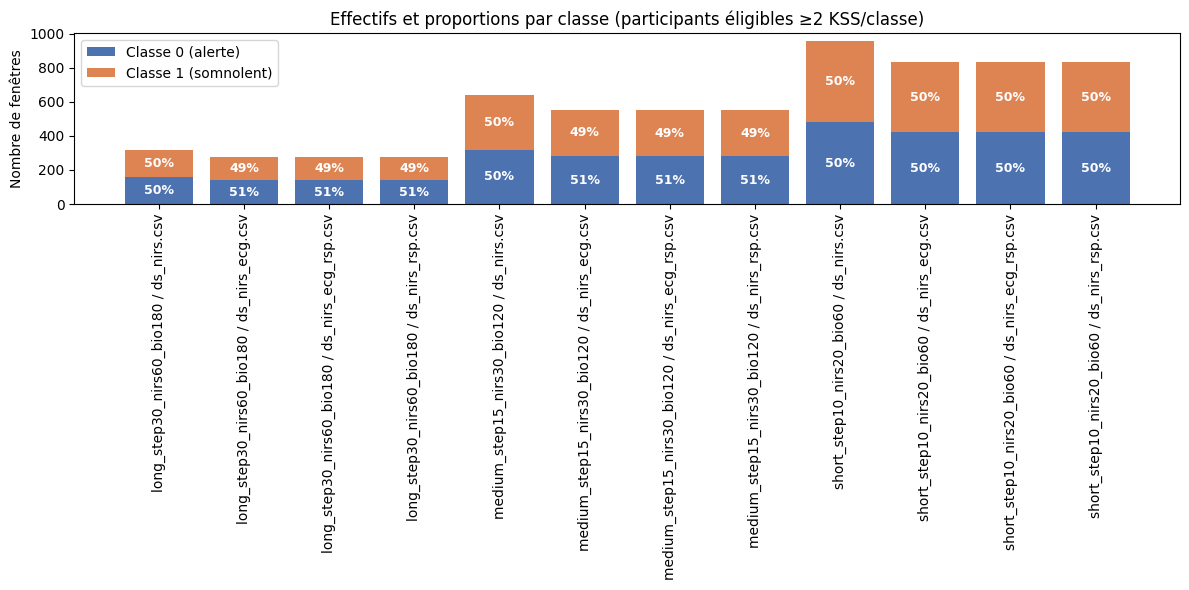

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

# --- Barres empilées ---
b0 = ax.bar(per_ds["dataset"], per_ds["class_0"],
            label="Classe 0 (alerte)", color="#4C72B0")
b1 = ax.bar(per_ds["dataset"], per_ds["class_1"], bottom=per_ds["class_0"],
            label="Classe 1 (somnolent)", color="#DD8452")

# --- Proportions inscrites dans chaque segment ---
for i in range(len(per_ds)):
    c0 = per_ds["class_0"].iloc[i]
    c1 = per_ds["class_1"].iloc[i]
    tot = c0 + c1
    if tot == 0:
        continue
    p0 = c0 / tot
    p1 = c1 / tot

    # Texte dans le segment bleu (classe 0) : au milieu de sa hauteur
    ax.text(i, c0 / 2, f"{p0:.0%}",
            ha="center", va="center", color="white", fontweight="bold", fontsize=9)

    # Texte dans le segment orange (classe 1) : au milieu de sa hauteur, au-dessus du bleu
    ax.text(i, c0 + c1 / 2, f"{p1:.0%}",
            ha="center", va="center", color="white", fontweight="bold", fontsize=9)

ax.set_ylabel("Nombre de fenêtres")
ax.set_title("Effectifs et proportions par classe (participants éligibles ≥2 KSS/classe)")
ax.set_xticks(range(len(per_ds)))
ax.set_xticklabels(per_ds["dataset"], rotation=90)
ax.legend()

plt.tight_layout()

# --- Enregistrement ---
path1 = os.path.join(FIG_DIR, "repartition_effectifs_proportions.png")
fig.savefig(path1, dpi=300, bbox_inches="tight")
print(f"Figure enregistrée : {path1}")

plt.show()


Figure enregistrée : RESULTS_ML_BY_PARTICIPANT_LEAVE_ONE_KSS_OUT-4FOLDScrossval\figures\repartition_taux_classe1.png


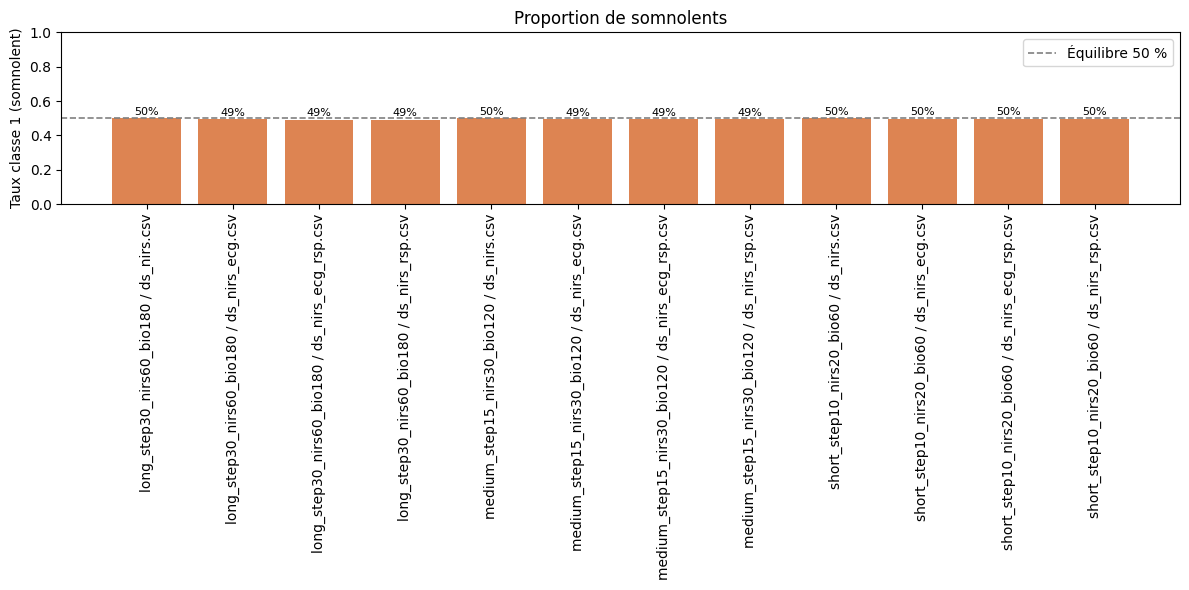

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(per_ds["dataset"], per_ds["class_1_rate"], color="#DD8452")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1.2, label="Équilibre 50 %")

ax.set_ylabel("Taux classe 1 (somnolent)")
ax.set_ylim(0, 1)
ax.set_title("Proportion de somnolents")
ax.tick_params(axis="x", rotation=90)

# Étiquettes de pourcentage au-dessus des barres
for b, r in zip(bars, per_ds["class_1_rate"]):
    ax.text(b.get_x() + b.get_width()/2, r + 0.02, f"{r:.0%}",
            ha="center", fontsize=8)

ax.legend()
plt.tight_layout()

# --- Enregistrement ---
path2 = os.path.join(FIG_DIR, "repartition_taux_classe1.png")
fig.savefig(path2, dpi=300, bbox_inches="tight")
print(f"Figure enregistrée : {path2}")

plt.show()
